In [1]:
import glob, os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, classification_report, confusion_matrix)

SEED = 42
print("Imports OK")

Imports OK


In [2]:
csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
if not csvs:
    import kagglehub
    folder = kagglehub.dataset_download("shivamb/real-or-fake-fake-jobposting-prediction")
    csvs = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)

print("CSV files found:", csvs)
assert csvs, "No CSV: attach the dataset via 'Add Input'."

CSV files found: ['/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv']


In [3]:
path = next((p for p in csvs if "fake" in p.lower() or "job" in p.lower()), csvs[0])
df = pd.read_csv(path)
assert "fraudulent" in df.columns, f"Wrong file loaded ({path})."
print("Loaded:", path)

Loaded: /kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv


In [4]:
print(df.shape)
print(df["fraudulent"].value_counts(normalize=True).round(3))
df.head(3)

(17880, 18)
fraudulent
0    0.952
1    0.048
Name: proportion, dtype: float64


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


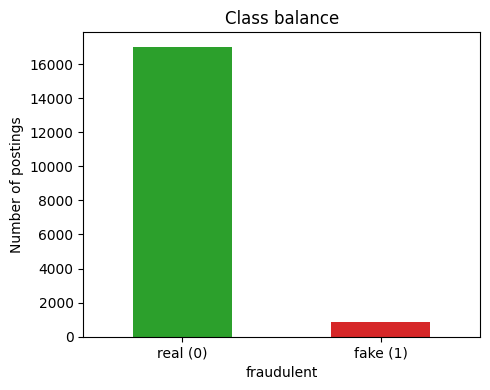

In [5]:
plt.figure(figsize=(5, 4))
df["fraudulent"].value_counts().sort_index().plot.bar(color=["tab:green", "tab:red"])
plt.xticks([0, 1], ["real (0)", "fake (1)"], rotation=0)
plt.title("Class balance")
plt.ylabel("Number of postings")
plt.tight_layout()
plt.savefig("eda_class_balance.png", dpi=150)
plt.show()

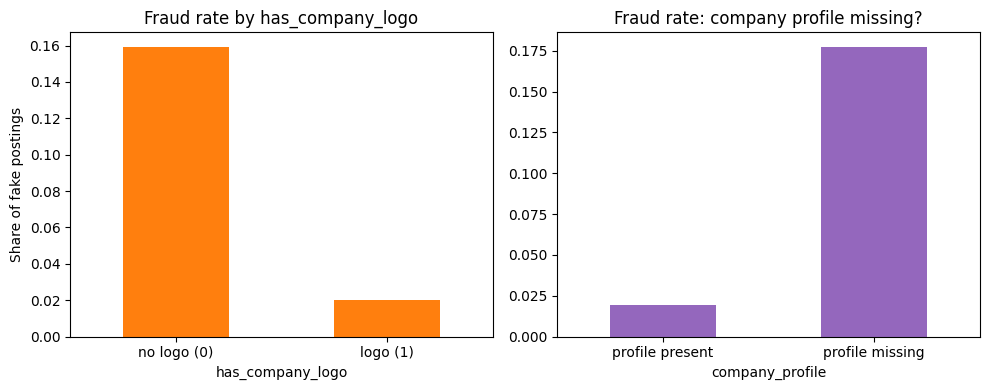

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

df.groupby("has_company_logo")["fraudulent"].mean().plot.bar(ax=ax[0], color="tab:orange")
ax[0].set_title("Fraud rate by has_company_logo")
ax[0].set_ylabel("Share of fake postings")
ax[0].set_xticklabels(["no logo (0)", "logo (1)"], rotation=0)

missing_profile = df["company_profile"].fillna("").eq("")
df.groupby(missing_profile)["fraudulent"].mean().plot.bar(ax=ax[1], color="tab:purple")
ax[1].set_title("Fraud rate: company profile missing?")
ax[1].set_xticklabels(["profile present", "profile missing"], rotation=0)

plt.tight_layout()
plt.savefig("eda_fraud_rates.png", dpi=150)
plt.show()

In [7]:
print("Accuracy of always predicting 'real':", round(1 - df["fraudulent"].mean(), 3))

Accuracy of always predicting 'real': 0.952


In [8]:
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
df[text_cols] = df[text_cols].fillna("")
df["text"] = df[text_cols].agg(" ".join, axis=1)
print(df["text"].str.len().describe().round(0))

count    17880.0
mean      2670.0
std       1466.0
min         18.0
25%       1595.0
50%       2522.0
75%       3475.0
max      14945.0
Name: text, dtype: float64


In [9]:
def clean(t):
    t = t.lower()
    t = re.sub(r"<[^>]+>", " ", t)                    # HTML tags
    t = re.sub(r"#url_[a-f0-9]+#", " tokurl ", t)
    t = re.sub(r"#email_[a-f0-9]+#", " tokemail ", t)
    t = re.sub(r"#phone_[a-f0-9]+#", " tokphone ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].map(clean)
print(df["clean"].iloc[0][:300])

marketing intern we re food and we ve created a groundbreaking and award winning cooking site we support connect and celebrate home cooks and give them everything they need in one place we have a top editorial business and engineering team we re focused on using technology to find new and better way


In [10]:
n0 = len(df)
df = df[df["clean"].str.len() > 20].drop_duplicates(subset="clean").reset_index(drop=True)
print(f"removed {n0 - len(df)} duplicate/empty postings, {len(df)} left")
print(df["fraudulent"].value_counts())

removed 2189 duplicate/empty postings, 15691 left
fraudulent
0    14984
1      707
Name: count, dtype: int64


In [11]:
df["has_url_token"]   = df["text"].str.contains("#URL_").astype(int)
df["has_email_token"] = df["text"].str.contains("#EMAIL_").astype(int)
df["has_phone_token"] = df["text"].str.contains("#PHONE_").astype(int)
df["no_profile"]      = (df["company_profile"] == "").astype(int)
df["no_requirements"] = (df["requirements"] == "").astype(int)
df["has_salary"]      = df["salary_range"].notna().astype(int)
df["text_len"]        = np.log1p(df["clean"].str.len()) / 10

meta_cols = ["telecommuting", "has_company_logo", "has_questions", "has_url_token", "has_email_token",
             "has_phone_token", "no_profile", "no_requirements", "has_salary", "text_len"]
print(df[meta_cols].mean().round(3))

telecommuting       0.043
has_company_logo    0.803
has_questions       0.493
has_url_token       0.288
has_email_token     0.073
has_phone_token     0.028
no_profile          0.194
no_requirements     0.137
has_salary          0.171
text_len            0.773
dtype: float64


In [12]:
tr_idx, te_idx = train_test_split(df.index, test_size=0.2, stratify=df["fraudulent"], random_state=SEED)
tr, te = df.loc[tr_idx], df.loc[te_idx]
ytr, yte = tr["fraudulent"].values, te["fraudulent"].values
print("train:", len(tr), "test:", len(te))

train: 12552 test: 3139


In [13]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, stop_words="english",
                      sublinear_tf=True, max_features=60_000)
Xtr = hstack([vec.fit_transform(tr["clean"]), csr_matrix(tr[meta_cols].values.astype(float))]).tocsr()
Xte = hstack([vec.transform(te["clean"]),     csr_matrix(te[meta_cols].values.astype(float))]).tocsr()
feature_names = np.array(list(vec.get_feature_names_out()) + meta_cols)
print(Xtr.shape, Xte.shape)

(12552, 60010) (3139, 60010)


In [14]:
models = {
    "LogReg (balanced)":    LogisticRegression(C=5, class_weight="balanced", max_iter=1000),
    "LinearSVC (balanced)": LinearSVC(C=0.5, class_weight="balanced"),
}
rows = []
for name, m in models.items():
    m.fit(Xtr, ytr)
    s = m.decision_function(Xte)
    rows.append({"model": name,
                 "PR_AUC": average_precision_score(yte, s),
                 "ROC_AUC": roc_auc_score(yte, s),
                 "F1_fraud (default threshold)": f1_score(yte, m.predict(Xte))})
pd.DataFrame(rows).round(3)

,model,PR_AUC,ROC_AUC,F1_fraud (default threshold)
0,LogReg (balanced),0.917,0.993,0.824
1,LinearSVC (balanced),0.923,0.993,0.879


In [15]:
best = LogisticRegression(C=5, class_weight="balanced", max_iter=1000)   # swap to LinearSVC(C=0.5, class_weight="balanced") if it won on PR-AUC

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
s_cv = cross_val_predict(best, Xtr, ytr, cv=cv, method="decision_function")
p, r, thr = precision_recall_curve(ytr, s_cv)

ok = np.where(p[:-1] >= 0.90)[0]
if len(ok):
    t = thr[ok[np.argmax(r[ok])]]        # max recall with precision >= 90%
    print("Threshold rule: max recall at precision >= 90%")
else:
    t = thr[np.argmax(2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9))]
    print("Threshold rule: best F1 (no threshold reached 90% precision)")
print("Chosen threshold:", round(float(t), 3))

Threshold rule: max recall at precision >= 90%
Chosen threshold: 0.949


In [16]:
best.fit(Xtr, ytr)
s_te = best.decision_function(Xte)
pred = (s_te >= t).astype(int)
print("done, predicted fake:", int(pred.sum()), "of", len(pred))

done, predicted fake: 116 of 3139


In [17]:
print(classification_report(yte, pred, target_names=["real", "fake"], digits=3))

              precision    recall  f1-score   support

        real      0.989     0.997     0.993      2998
        fake      0.931     0.766     0.840       141

    accuracy                          0.987      3139
   macro avg      0.960     0.882     0.917      3139
weighted avg      0.986     0.987     0.986      3139



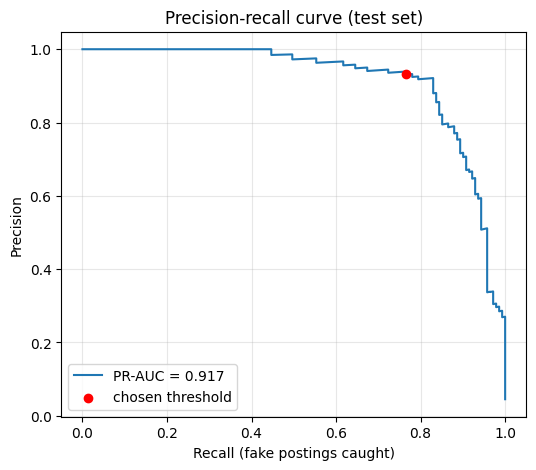

In [18]:
pt, rt, _ = precision_recall_curve(yte, s_te)
plt.figure(figsize=(6, 5))
plt.plot(rt, pt, label=f"PR-AUC = {average_precision_score(yte, s_te):.3f}")
plt.scatter([recall_score(yte, pred)], [precision_score(yte, pred)], c="red", zorder=3, label="chosen threshold")
plt.xlabel("Recall (fake postings caught)"); plt.ylabel("Precision")
plt.legend(); plt.grid(alpha=.3)
plt.title("Precision-recall curve (test set)")
plt.savefig("pr_curve.png", dpi=150)
plt.show()

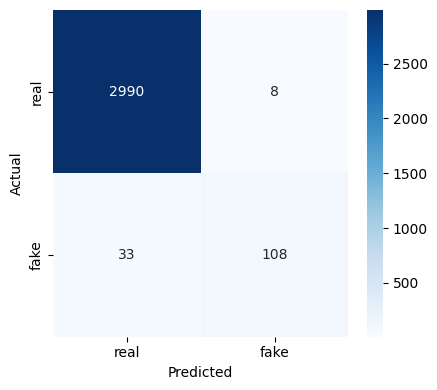

In [19]:
cm = confusion_matrix(yte, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["real", "fake"], yticklabels=["real", "fake"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

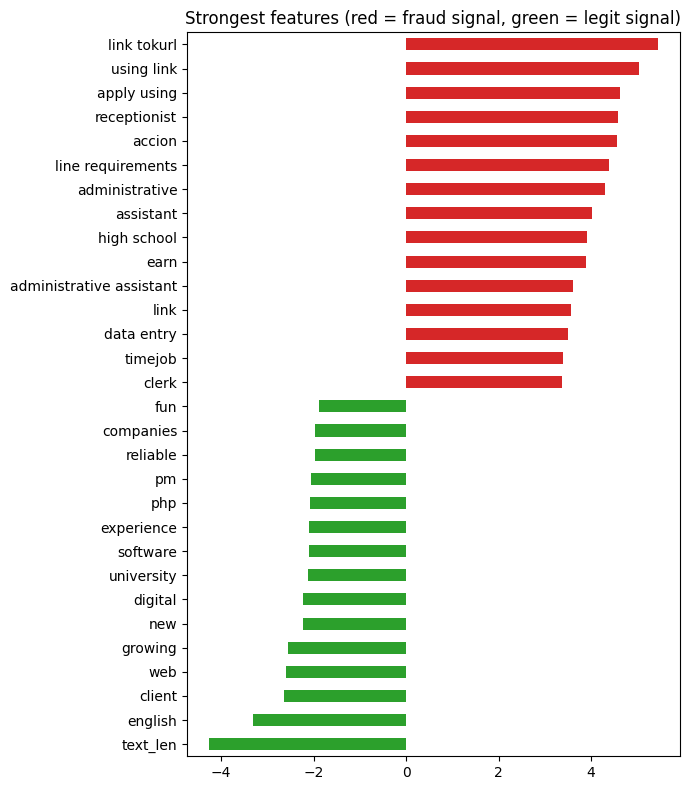

In [20]:
coef = pd.Series(best.coef_[0], index=feature_names)
top = pd.concat([coef.nsmallest(15), coef.nlargest(15)]).sort_values()
top.plot.barh(figsize=(7, 8), color=["tab:green" if v < 0 else "tab:red" for v in top],
              title="Strongest features (red = fraud signal, green = legit signal)")
plt.tight_layout()
plt.savefig("top_features.png", dpi=150)
plt.show()

In [21]:
res = te[["title", "fraudulent"]].copy()
res["score"] = s_te
res["pred"] = pred
display(res[(res.fraudulent == 1) & (res.pred == 0)].sort_values("score").head(5))

,title,fraudulent,score,pred
3235,Business Development Manager,1,-2.587335,0
5922,Urgent position for SQL BI Tester,1,-2.435818,0
5792,"Resources Change Management, Process Excelle...",1,-2.344191,0
14902,"Quality Specialist II, Clinical Programming",1,-2.281364,0
1092,Big Data Engineer,1,-1.987267,0


In [22]:
display(res[(res.fraudulent == 0) & (res.pred == 1)].sort_values("score", ascending=False).head(5))

,title,fraudulent,score,pred
13087,Payroll Clerk $20/hr,0,3.260256,1
3818,Accounting Assistant,0,2.963237,1
5803,Sales Representative,0,2.622524,1
229,Data Entry/Customer Service Rep,0,2.258238,1
7511,Accounting Clerk $15/hr,0,1.991982,1


In [23]:
tp = int(((pred == 1) & (yte == 1)).sum()); fn = int(((pred == 0) & (yte == 1)).sum())
fp = int(((pred == 1) & (yte == 0)).sum()); tn = int(((pred == 0) & (yte == 0)).sum())

print("Postings after cleaning:", len(df))
print("Train / test sizes:", len(ytr), "/", len(yte))
print("PR-AUC (test):", round(average_precision_score(yte, s_te), 3))
print("Chosen threshold:", round(float(t), 3))
print(f"Precision: {precision_score(yte, pred):.3f}   Recall: {recall_score(yte, pred):.3f}   F1: {f1_score(yte, pred):.3f}")
print(f"Caught {tp} of {tp + fn} fake postings, with {fp} false alarms among {fp + tn} real postings")

Postings after cleaning: 15691
Train / test sizes: 12552 / 3139
PR-AUC (test): 0.917
Chosen threshold: 0.949
Precision: 0.931   Recall: 0.766   F1: 0.840
Caught 108 of 141 fake postings, with 8 false alarms among 2998 real postings


In [24]:
print(sorted(f for f in os.listdir("/kaggle/working") if f.endswith(".png")))

['confusion_matrix.png', 'eda_class_balance.png', 'eda_fraud_rates.png', 'pr_curve.png', 'top_features.png']
